In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy, scipy.interpolate
import time
import baccoemu
from scipy.optimize import minimize
import sys, platform, os
from multiprocessing import Pool
import emcee
from astropy import constants as const
import scipy.integrate as integrate
import scipy.interpolate as interpolate
from multiprocessing import Pool
from scipy.stats import multivariate_normal

2026-01-26 20:11:51.093626: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-26 20:11:53.447779: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-26 20:11:53.454326: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-26 20:11:55.041923: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-01-26 20:11:57.072558: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [2]:
l_speed = const.c.value / 1000 
h0=0.67

In [3]:
N_int=20

def E(z, Omegam, w0):
    mat = Omegam * (1 + z) ** 3
    de = (1-Omegam) *(1 + z) ** (3 * (1 + w0))

    return np.sqrt(mat + de)

def Ez(u,Omegam, w0):
    return 1/E(u,Omegam, w0)


def r(z, Omegam,  w0):
    #def integrand(u):
    #    return f(u, Omegam,wa,w0)
    z_int = np.linspace(0, z, N_int)
    #print(z_int)
    integral = np.trapz(Ez(z_int,Omegam,w0), z_int)
    return integral * l_speed / (h0 * 100)

r_vec=np.vectorize(r)

In [4]:
r_vec([0.0001,0.02], 0.3,-1)

array([ 0.44744136, 89.08587343])

In [5]:
#r_vec=np.vectorize(r)

z_equipop_bins = [(0.001, 0.42), (0.42, 0.56), (0.56, 0.68), (0.68, 0.79), (0.79, 0.90),
                    (0.90, 1.02), (1.02, 1.15) ,(1.15, 1.32), (1.32, 1.58), (1.58, 2.50)]

def n(z, zm=0.9):
    """Underlying distribution of density.
    This expression is chosen in agreement with Euclid
    Red Book. Note that this does NOT take into account
    the proportional constant.
    ===================================================
    Inputs: redshift z, median redshift zp (optional,
    default is 0.9 according to Euclid Red Book)
    Output: number density at redshift z.
    """
    z0 = zm / np.sqrt(2)
    return (z / z0) ** 2 * np.exp(-(z / z0) ** (3 / 2))

def window(z,Omegam, w0,r_denom1,zmax=2.5):
    """Reduced window function as a function of redshift.
    trapz from numpy is used for integration.
    ===================================================
    Inputs: bin number i, redshift z, min/max redshift 
    zmin/zmax (optional, default=0.001/2.5)
    Output: window function evaluated at z, of the ith bin.
    """
    def integrand(w):
        return (n(w)/0.4227) * (1 - r_denom1 / r_vec(w,Omegam, w0))
    
    z_int = np.linspace(z, zmax, N_int)
    integral = np.trapz(integrand(z_int), z_int)

    return integral

def weight(z, Omegam, w0, r_denom1):
    constant = 3 / 2 * (67 / l_speed) ** 2 * Omegam
    z_dep = (1 + z) * window(z,Omegam, w0, r_denom1)
    return constant*z_dep 

ee2 =baccoemu.Matter_powerspectrum()
k_custom = np.logspace(-3.5, np.log10(ee2.emulator['nonlinear']['k'].max()), num=100)

def cosmo(z,Omegam, w0, s8):
    a1=1./(1+z)

    cosmo_par = {
    'omega_cold'    :  Omegam,
    'sigma8_cold'   :  s8, # if A_s is not specified
    'omega_baryon'  :  0.05,
    'ns'            :  0.96,
    'hubble'        :  h0,
    'neutrino_mass' :  0.0,
    'w0'            : w0,
    'wa'            :  0,
    'expfactor'     :  a1
}
    return cosmo_par

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator...
Baryonic Emulator loaded in memory.


/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/sklearn/base.py:348: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.0 when using version 1.3.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/sklearn/base.py:348: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.0 when using version 1.3.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/sklearn/base.py:348: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.0.2 when using versio

In [6]:
redshifts=np.array([0.001, 0.42,0.56,0.68,0.79,0.9,1.02,1.15,1.32,1.5])
Nbins=11
ls = np.logspace(np.log10(10), np.log10(2000), Nbins)

l_bins = [(ls[i], ls[i + 1]) for i in range(Nbins-1)]
ls_eval = np.array([(l_bins[i][1] + l_bins[i][0]) / 2 for i in range(Nbins-1)])

print(ls_eval,len(ls_eval))
print(l_bins)

def mps_fiducial(z,k,redshifts, k1, pnl_array):

    mps = interpolate.RectBivariateSpline(redshifts,k1, pnl_array)
    return mps(z,k)




[  13.49323232   22.92023138   38.93337001   66.13403132  112.33833849
  190.82312152  324.14102073  550.60099891  935.27644023 1588.70401865] 10
[(10.0, 16.986464646342473), (16.986464646342473, 28.853998118144272), (28.853998118144272, 49.01274189394899), (49.01274189394899, 83.25532074018732), (83.25532074018732, 141.4213562373095), (141.4213562373095, 240.22488679628626), (240.22488679628626, 408.05715467367395), (408.05715467367395, 693.1448431551464), (693.1448431551464, 1177.4080373049494), (1177.4080373049494, 2000.0000000000002)]


In [7]:
def convergence(l, Omegam, w0, s8, zmin=0.001, zmax=2.5):
    H0 = h0 * 100
    pnl=[]
    #start=time.time()
    for redshift in redshifts:
        k1, pnl_2 = ee2.get_nonlinear_pk(k=k_custom, cold=True, **cosmo(redshift,Omegam,w0,s8)) ### BACCO emu
        pnl.append(pnl_2)

    pnl_array=np.array(pnl)
    #print(time.time()-start)
    def integrand(z,ell, Omegam, w0):
        r_denom=r_vec(z,Omegam, w0)
        #print('z: ',z,'r_denom: ',r_denom)
        w1=weight(z, Omegam, w0,r_denom) **2
        term1 =w1/(E(z,Omegam, w0))

        
        k = (ell + 0.5) / r_denom
    
        term2 = interpolate.RectBivariateSpline(redshifts,k1, pnl_array)
        #mps_fiducial(z, k, redshifts, k1, pnl_array)[0]

        return  term1 * term2(z,k)[0]
    
   
    integral = integrate.quad(integrand, zmin, zmax,args=(l, Omegam,  w0))[0]
    #print(l_speed)
    #z_int = np.linspace(zmin, zmax, N_int)
    #print(z_int)
    #integral = np.trapz(integrand(z_int,l,Omegam,w0), z_int)
    
    return l_speed / H0 *integral

def convergence_baryons(l, Omegam, w0, s8, ratio,zmin=0.001, zmax=2.5):
    H0 = h0 * 100
    pnl=[]
    #start=time.time()
    for redshift in redshifts:
        k1, pnl_2 = ee2.get_nonlinear_pk(k=k_custom, cold=True, **cosmo(redshift,Omegam,w0,s8)) ### BACCO emu
        pnl.append(pnl_2)

    pnl_array=np.array(pnl)
    #print(time.time()-start)
    def integrand(z,ell, Omegam, w0):
        r_denom=r_vec(z,Omegam, w0)
        #print('z: ',z,'r_denom: ',r_denom)
        w1=weight(z, Omegam, w0,r_denom) **2
        term1 =w1/(E(z,Omegam, w0))

        
        k = (ell + 0.5) / r_denom
    
        term2 = interpolate.RectBivariateSpline(redshifts,k1, pnl_array)
        #mps_fiducial(z, k, redshifts, k1, pnl_array)[0]

        return term1 * term2(z,k)[0]*ratio(z,k)
    
   
    integral = integrate.quad(integrand, zmin, zmax,args=(l, Omegam,  w0))[0]

    #z_int = np.linspace(zmin, zmax, N_int)
    #print(z_int)
    #integral = np.trapz(integrand(z_int,l,Omegam,w0), z_int)
    
    return l_speed / 67 *integral


#convergence=np.vectorize(convergence)
#convergence_baryons=np.vectorize(convergence_baryons)

In [8]:
def cl_pool(input1):
    ell,om,w0,s8=input1
    return convergence(ell,om,w0,s8)


def run_cl_pool(ls_eval,om,w0,s8):
    #global ls_eval
    pool=Pool()
    input1=[[ell,om,w0,s8] for ell in ls_eval]
    return pool.map(cl_pool,input1)

In [9]:
start=time.time()
stat_obs=run_cl_pool(ls_eval, 0.32, -1, 0.83)
print(stat_obs)
print('Data vector obs done. Time: ', time.time()-start)
#np.save('stat_obs_dmo_notarandomrealization.npy',stat_obs)

[1.082505598254996e-08, 9.517698346763195e-09, 7.101740730149202e-09, 4.583299735092078e-09, 2.651587923062313e-09, 1.3775997879288055e-09, 6.908670781031928e-10, 3.507775366090072e-10, 1.8636194091453683e-10, 1.0145649001446488e-10]
Data vector obs done. Time:  0.5132336616516113


## Noe we generate a data vector from bacco with Mc fixed. We aim to recover it

In [ ]:
h00=0.67
H0=h00*100
ee2 =baccoemu.Matter_powerspectrum()
k_custom = np.logspace(-3.5, np.log10(ee2.emulator['nonlinear']['k'].max()), num=100)

def cosmo(z,Omegam, w0, s8,mc1):
    a1=1./(1+z)

    cosmo_par = {
    'omega_cold'    :  Omegam,
    'sigma8_cold'   :  s8, # if A_s is not specified
    'omega_baryon'  :  0.05,
    'ns'            :  0.96,
    'hubble'        :  h00,
    'neutrino_mass' :  0.0,
    'w0'            : w0,
    'wa'            :  0,
    'expfactor'     :  a1,
    'M_c'           :  mc1,
    'eta'           : -0.3,
    'beta'          : -0.22,
    'M1_z0_cen'     : 10.5,
    'theta_out'     : 0.25,
    'theta_inn'     : -0.86,
    'M_inn'         : 13.4
}

    return cosmo_par


# In[22]:


redshifts=np.array([0.001, 0.42,0.56,0.68,0.79,0.9,1.02,1.15,1.32,1.5])
Nbins=11
ls = np.logspace(np.log10(10), np.log10(2000), Nbins)

l_bins = [(ls[i], ls[i + 1]) for i in range(Nbins-1)]
ls_eval = np.array([(l_bins[i][1] + l_bins[i][0]) / 2 for i in range(Nbins-1)])
Nbins=len(ls_eval)
print('multipoles number of bins:',ls_eval,Nbins)


def mps_fiducial(z,k,redshifts, k1, pnl_array):

    mps = interpolate.RectBivariateSpline(redshifts,k1, pnl_array)
    return mps(z,k)

#stat_obs=np.load('stat_obs_dmo_randomrealization.npy',allow_pickle=True)
##np.load('stat_obs_noisy_baryons.npy',allow_pickle=True)
## np.load('stat_obs_dmo_notarandomrealization.npy',allow_pickle=True)#

def convergence_baryons(l, Omegam, w0, s8,mc1,zmin=0.001, zmax=2.5):
    pnl=[]
    #start=time.time()
    for redshift in redshifts:
        k1, pnl_2 = ee2.get_nonlinear_pk(k=k_custom, baryonic_boost=True,cold=True, **cosmo(redshift,Omegam,w0,s8,mc1)) ### BACCO emu
        pnl.append(pnl_2)

    pnl_array=np.array(pnl)
 
    def integrand(z,ell, Omegam, w0):
        r_denom=r_vec(z,Omegam, w0)
        w1=weight(z, Omegam, w0,r_denom) **2
        term1 =w1/(E(z,Omegam, w0))

        
        k = (ell + 0.5) / r_denom
    
        term2 = interpolate.RectBivariateSpline(redshifts,k1, pnl_array)
        

        return term1 * term2(z,k)[0]
    
   
    integral = integrate.quad(integrand, zmin, zmax,args=(l, Omegam,  w0))[0]

    
    return l_speed / H0 *integral


# In[30]:


import scipy.interpolate as interpolate
from scipy.interpolate import LinearNDInterpolator

ratios=os.listdir('/home/daniela/Documents/EuclidEmulator2-pywrapper/Daniela/')
ranges_z=[1001*n for n in range(1,101)]
del ratios[3]
    
import warnings
warnings.filterwarnings("ignore")

home='/home/daniela/Documents/EuclidEmulator2-pywrapper/Daniela/'
ranges_z=[1001*n for n in range(1,101)]


#covmat=np.load('covmat.npy',allow_pickle=True)
#print('shape covmat: ', covmat.shape)

def cl_pool_baryons(input1):
    ell,om,w0,s8,mc1=input1
    return convergence_baryons(ell,om,w0,s8,mc1)



def run_cl_pool(ls_eval,om,w0,s8,mc1):
    #global ls_eval
    pool=Pool()
    input1=[[ell,om,w0,s8,mc1] for ell in ls_eval]
    return pool.map(cl_pool_baryons,input1)

def model(Omegam, w0, s8,mc1):
    
    return run_cl_pool(ls_eval,Omegam,w0, s8,mc1)

In [ ]:
start=time.time()
stat_obs=model(0.32, -1, 0.83,12)
print(stat_obs)
print('Data vector obs done. Time: ', time.time()-start)
#np.save('stat_obs_bacco_mc12_notarandomrealization.npy',stat_obs)

                


                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
          

                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                

                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
           

                

                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapolating
                to 4.903235148249275 h/Mpc; the extrapolation will likely be not
                accurate.
                
                The maximum k of the baryonic boost emulator is 4.692772528625323
                h/Mpc: the baryonic emulator is currently extrapol

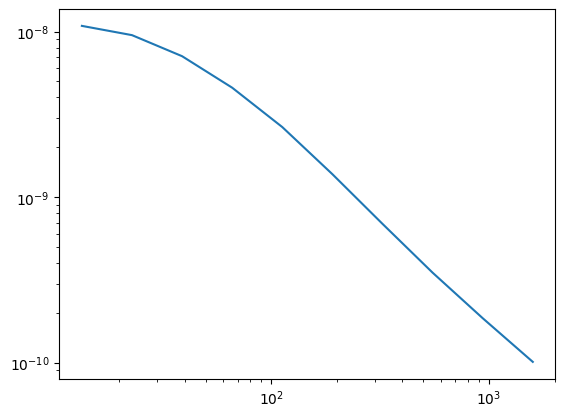

In [16]:
plt.loglog(ls_eval,stat_obs)

## Now noisy realization of a dark matter only data vector

In [39]:
mean_n_arcmin=30

mean_n_ster=mean_n_arcmin*(60**2)*(180/np.pi)**2

shape_noise=(0.25**2)/(mean_n_ster)
print(np.ones(len(ls_eval))*shape_noise)

[1.76283229e-10 1.76283229e-10 1.76283229e-10 1.76283229e-10
 1.76283229e-10 1.76283229e-10 1.76283229e-10 1.76283229e-10
 1.76283229e-10 1.76283229e-10]


In [51]:
diag_cov=np.diag(np.load('covmat.npy'))
np.sqrt(diag_cov)

array([1.31921398e-09, 6.88668957e-10, 3.04795874e-10, 1.16888182e-10,
       4.04199339e-11, 1.27420227e-11, 3.98890648e-12, 1.32352052e-12,
       4.87385012e-13, 1.98199664e-13])

In [66]:
ckk_obs=[]
random_seed1=9
for i in range(len(ls_eval)):
    np.random.seed(random_seed1)
    ckk_obs.append(np.random.normal(stat_obs[i],diag_cov[i]*100000000))
    random_seed1+=1
    
print(ckk_obs)
np.save('stat_obs_Mc12_randomrealization_7jan.npy',ckk_obs)

[1.0824579764932852e-08, 9.579489882596098e-09, 7.116875115775902e-09, 4.582550298858081e-09, 2.650191499057828e-09, 1.3765403298940548e-09, 6.899907153187537e-10, 3.500368658849304e-10, 1.8582012063153133e-10, 1.0122081580737649e-10]


In [67]:
np.array(ckk_obs)/stat_obs ##+np.ones(len(ls_eval))*shape_noise

array([1.00001782, 1.00663622, 1.00228889, 1.00014104, 0.99995608,
       1.0000183 , 0.99999928, 1.00000006, 1.00000004, 1.        ])

In [11]:
#start=time.time()
#stat_obs=convergence(ls_eval, 0.32, 0, -1, 0.83, zmin=0.001, zmax=2.5)
#print(stat_obs)
#print('Data vector obs done. Time: ', time.time()-start)

In [11]:
import scipy.interpolate as interpolate
from scipy.interpolate import LinearNDInterpolator

ratios=os.listdir('/home/daniela/Documents/EuclidEmulator2-pywrapper/Daniela/')
ranges_z=[1001*n for n in range(1,101)]
del ratios[3]

to_remove=['power_suppression_Illustris-1_highres.dat','power_suppression_Hz-AGN_highres.dat',
          'power_suppression_TNG100-1_highres.dat','power_suppression_SIMBA_highres.dat',
           'power_suppression_TNG300-1_highres.dat','power_suppression_C-OWLS_AGN_Theat8.3_WMAP7_highres.dat',
          'power_suppression_C-OWLS_AGN_WMAP7_L200N512_highres.dat','power_suppression_EAGLE_REF_highres.dat',
           'power_suppression_C-OWLS_AGN_WMAP7_L200N1024_highres.dat',
          'power_suppression_BAHAMAS_nu0_BAO_L200N512_highres.dat','power_suppression_OWLS_WML4_highres.dat']

for rem in to_remove:
    ratios.remove(rem)
    
import warnings
warnings.filterwarnings("ignore")

home='/home/daniela/Documents/EuclidEmulator2-pywrapper/Daniela/'
ranges_z=[1001*n for n in range(1,101)]

def ratio_func(ratio1):
    
    with open(home+ratio1) as f2:
        a_data=[line.split() for line in f2]
        
    f2.close()
    #print(len(a))
    data=a_data[2:]
    #print(np.array(data[0])[:,0])
    data1=[]
    zvalues=[]
    for limit1 in range(len(ranges_z)):
        for_interp=[]
        element=data[ranges_z[limit1]-1001:ranges_z[limit1]]
        for ii in element:
            for_interp.append([float(ii[1]),float(ii[2])])

        data1.append(for_interp)

    data1=np.array(data1)

    ranges_k=np.array(data1[0])[:,0]
    
    mps_fiducial = interpolate.RectBivariateSpline(ranges_z,ranges_k, data1[:,:,1])
    return mps_fiducial

8.814161452161706e-11


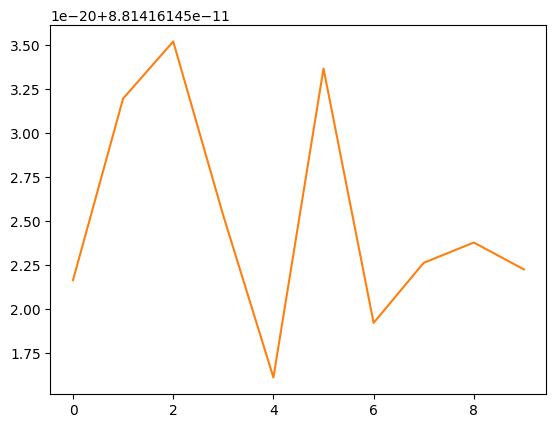

In [29]:
mean_n_arcmin=30

mean_n_ster=mean_n_arcmin*(60**2)*(180/np.pi)**2

shape_noise=(0.25**2)/(2*mean_n_ster)
print(shape_noise)
random_seed1=9

noisy_noise=[]
for i in range(len(ls_eval)):
    np.random.seed(random_seed1)
    noisy_noise.append(np.random.normal(0,shape_noise**2))
    random_seed1+=1

    
    #multivariate_normal.rvs(mean=cosmic_shear[7,:],cov=np.identity(100)*shape_noise,random_state=rseed)
noisy_noise=np.array(noisy_noise)+shape_noise

plt.plot(shape_noise)
plt.plot(noisy_noise)
plt.show()

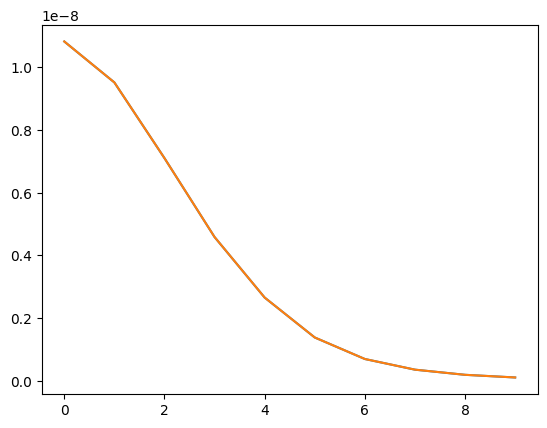

[1.         1.00000001 1.         1.         1.         1.
 1.         1.         1.         1.        ]


In [30]:

ckk_obs=[]
for i in range(len(ls_eval)):
    np.random.seed(random_seed1)
    ckk_obs.append(np.random.normal(stat_obs[i],stat_obs[i]**2))
    random_seed1+=1
    
plt.plot(stat_obs)
plt.plot(ckk_obs)
plt.show()

print(np.array(ckk_obs)/np.array(stat_obs))

Text(0.5, 1.0, 'Lensing power spectrum')

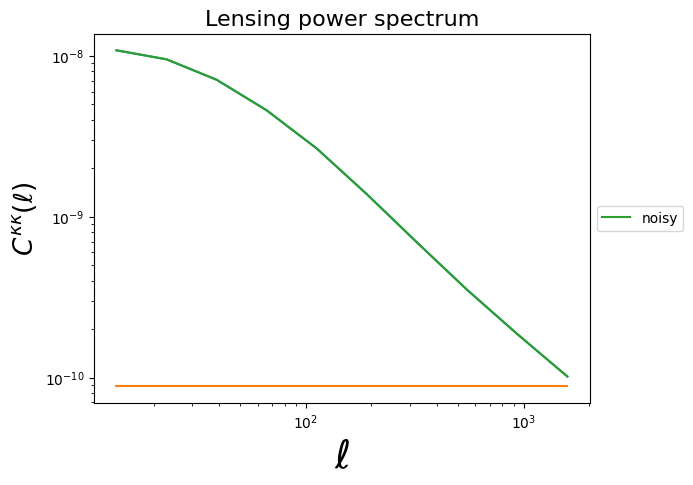

In [14]:
fig, ax = plt.subplots()


ax.plot(ls_eval, stat_obs)
ax.plot(ls_eval, noisy_noise)
ax.plot(ls_eval, ckk_obs,label='noisy')
ax.set_xlabel('$\ell$',fontsize=28)
ax.set_ylabel(r'$C^{\kappa\kappa}(\ell)$',fontsize=19);
ax.set_xscale('log')
ax.set_yscale('log')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title('Lensing power spectrum',fontsize=16)


In [17]:
def covariance(fsky=0.35):
    N_length=len(ls_eval)
    covariance_matrix = np.zeros((N_length, N_length))
    for idx in range(N_length):
   
        num1 = (ckk_obs[idx]+noisy_noise[idx]) ** 2
        
        covariance_matrix[idx, idx] = num1 / ((2 * ls_eval[idx] + 1) * fsky*(l_bins[idx][1]-l_bins[idx][0]))
    return covariance_matrix

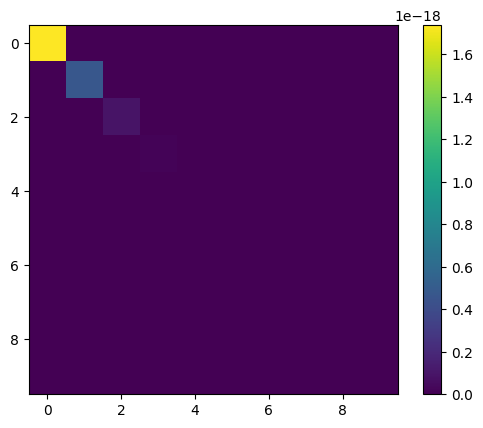

In [18]:
covmat=covariance(fsky=0.35)
plt.imshow(covmat)
plt.colorbar()
plt.show()

In [31]:
#np.save('covmat.npy',covmat)

In [19]:
ratio_b=ratio_func('power_suppression_C-OWLS_AGN_Mseed800_Theat8.7_WMAP7_L100N512_highres.dat')

#start=time.time()
stat_obs=run_cl_pool(ls_eval,om,w0,s8,ratio_b)(ls_eval,0.32, -1, 0.83, ratio_b,ratio_b)
print(stat_obs)
#print('Data vector obs done. Time: ', time.time()-start)


ckk_obs=[]
for i in range(len(ls_eval)):
    np.random.seed(random_seed1)
    ckk_obs.append(np.random.normal(stat_obs[i],stat_obs[i]**2*10000))
    random_seed1+=1
    
#plt.plot(stat_obs)
#plt.plot(ckk_obs)
#plt.show()

#stat_obs_noisy=np.array(ckk_obs)#+noisy_noise



NameError: name 'om' is not defined

In [ ]:
len(ratios)

In [ ]:
#model 3ratio_b=ratio_func('power_suppression_OWLS_NOSN_highres.dat')
# model 2ratio_b=ratio_func('power_suppression_BAHAMAS_nu0_WMAP9_v3_highres.dat')
#MODEL 1:ratio_b=ratio_func('power_suppression_C-OWLS_AGN_Mseed800_Theat8.7_WMAP7_L100N512_highres.dat')
#ratio_b=ratio_func('power_suppression_BAHAMAS_nu0_WMAP9_v3_highres.dat')
ratio_b=ratio_func('power_suppression_C-OWLS_NOCOOL_UVB_WMAP7_L100N256_highres.dat')

stat_obs_noisy=np.array(ckk_obs)

def cl_pool_baryons(input1):
    ell,om,w0,s8,ratio_b=input1
    return convergence_baryons(ell,om,w0,s8,ratio_b)
#def cl_pool(input1):
#    ell,om,w0,s8=input1
#    return convergence(ell,om,w0,s8,ratio_b)


def run_cl_pool(ls_eval,om,w0,s8,ratio_b):
    #global ls_eval
    pool=Pool()
    input1=[[ell,om,w0,s8,ratio_b] for ell in ls_eval]
    return pool.map(cl_pool_baryons,input1)


def model(Omegam, w0, s8):
    
    return run_cl_pool(ls_eval,Omegam,w0, s8,ratio_b)
# return convergence_baryons(ls_eval,Omegam,wa,w0, s8,ratio_b)

invcov = np.linalg.inv(covmat)

def lnprior(theta):
    Omegam,w0, s8 = theta
    if 0.23 < Omegam < 0.4 and -1.15 < w0 < -0.85 and 0.73<s8<0.9:
        return 0.0
    return -np.inf

def chisq(Omegam,w0,s8):

    
    model1=np.array(model(Omegam,w0,s8)) #+ shape_noise

    diff = stat_obs_noisy-model1
    #print(diff)

    return np.sum(((diff)**2)*np.diag(invcov))

def lnlikelihood(theta):
    Omegam,w0,s8 = theta
    #print(theta)
    model = chisq(Omegam,w0,s8)
    return -0.5*model

def lnprob(theta):
    lp = lnprior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlikelihood(theta)


In [20]:
chisq(0.32,-1,0.83)

NameError: name 'chisq' is not defined

[1.0824358206430145e-08, 9.516433011106322e-09, 7.09949677451084e-09, 4.579704724072118e-09, 2.6462342381778383e-09, 1.3708856054395795e-09, 6.831924612006431e-10, 3.429572843712808e-10, 1.7914678144179114e-10, 9.641106546364105e-11]


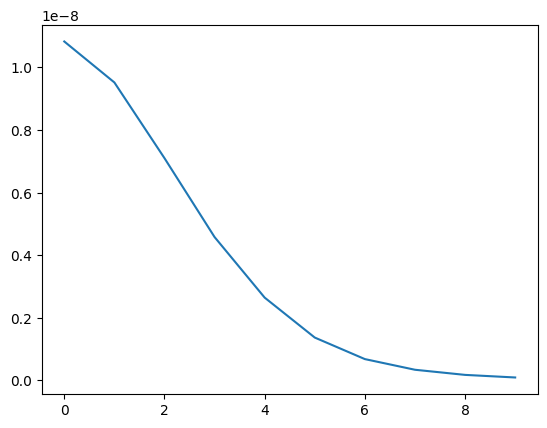

[1.         0.99999999 1.         1.         1.         1.
 1.         1.         1.         1.        ]


In [21]:
ratio_b=ratio_func('power_suppression_BAHAMAS_nu0.06_Planck2015_highres.dat')

#start=time.time()
stat_obs=run_cl_pool(ls_eval, 0.32, -1, 0.83,ratio_b)#(ls_eval,0.32, -1, 0.83, ratio_b,ratio_b)
print(stat_obs)
#print('Data vector obs done. Time: ', time.time()-start)


ckk_obs=[]
for i in range(len(ls_eval)):
    np.random.seed(random_seed1)
    ckk_obs.append(np.random.normal(stat_obs[i],stat_obs[i]**2))
    random_seed1+=1
    
#plt.plot(stat_obs)
plt.plot(ckk_obs)
plt.show()

stat_obs_noisy=np.array(ckk_obs)#+noisy_noise
print(stat_obs_noisy/stat_obs)

In [25]:
#np.save('stat_obs_noisy_baryons.npy',stat_obs_noisy)

In [24]:
chisq(0.4, -0.9625160190926394, 0.8838213402390946)

204277.42763035596

In [23]:
chimin =lambda x: -lnprob(x)

start=time.time()
dres=[0.01,0.01,0.01]
rest=minimize(chimin,[0.3,-1,0.83],method='Nelder-Mead')
result=rest.x
#result=[0.3576624801425927, -0.0008293451957912797, -0.8500002144503158, 0.8759714487949265]

print(result[0],result[1],result[2])

print(time.time()-start)#

print('Running MCMC..')

Process ForkPoolWorker-184:
Process ForkPoolWorker-182:
Process ForkPoolWorker-178:
Process ForkPoolWorker-190:
Process ForkPoolWorker-189:
Process ForkPoolWorker-179:
Process ForkPoolWorker-186:
Process ForkPoolWorker-187:
Process ForkPoolWorker-185:
Process ForkPoolWorker-191:
Process ForkPoolWorker-181:
Process ForkPoolWorker-183:
Process ForkPoolWorker-192:
Process ForkPoolWorker-177:
Process ForkPoolWorker-188:
Process ForkPoolWorker-180:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  

  File "/usr/lib/python3.8/multiprocessing/queues.py", line 355, in get
    with self._rlock:
  File "/usr/lib/python3.8/multiprocessing/connection.py", line 216, in recv_bytes
    buf = self._recv_bytes(maxlength)
  File "/usr/lib/python3.8/multiprocessing/queues.py", line 355, in get
    with self._rlock:
KeyboardInterrupt
  File "/tmp/ipykernel_4508/3507892001.py", line 59, in convergence_baryons
    integral = integrate.quad(integrand, zmin, zmax,args=(l, Omegam,  w0))[0]
  File "/tmp/ipykernel_4508/307458814.py", line 11, in cl_pool_baryons
    return convergence_baryons(ell,om,w0,s8,ratio_b)
KeyboardInterrupt
KeyboardInterrupt
  File "/usr/lib/python3.8/multiprocessing/queues.py", line 355, in get
    with self._rlock:
  File "/usr/lib/python3.8/multiprocessing/pool.py", line 48, in mapstar
    return list(map(*args))
KeyboardInterrupt
KeyboardInterrupt
  File "/usr/lib/python3.8/multiprocessing/connection.py", line 414, in _recv_bytes
    buf = self._recv(4)
  File "/usr/lib/pyt

KeyboardInterrupt: 

  File "/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/scipy/integrate/_quadpack_py.py", line 463, in quad
    retval = _quad(func, a, b, args, full_output, epsabs, epsrel, limit,
  File "/tmp/ipykernel_4508/3507892001.py", line 59, in convergence_baryons
    integral = integrate.quad(integrand, zmin, zmax,args=(l, Omegam,  w0))[0]
  File "/tmp/ipykernel_4508/3637693780.py", line 28, in integrand
    return (n(w)/0.4227) * (1 - r_denom1 / r_vec(w,Omegam, w0))
  File "/usr/lib/python3.8/multiprocessing/connection.py", line 379, in _recv
    chunk = read(handle, remaining)
  File "/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/numpy/lib/function_base.py", line 2329, in __call__
    return self._vectorize_call(func=func, args=vargs)
  File "/home/daniela/cl_bma_nonconda38/lib/python3.8/site-packages/scipy/integrate/_quadpack_py.py", line 575, in _quad
    return _quadpack._qagse(func,a,b,args,full_output,epsabs,epsrel,limit)
  File "/home/daniela/cl_bma_nonconda3

In [79]:
rest

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 7.205176296048689e-06
             x: [ 3.200e-01 -1.000e+00  8.300e-01]
           nit: 114
          nfev: 211
 final_simplex: (array([[ 3.200e-01, -1.000e+00,  8.300e-01],
                       [ 3.200e-01, -1.000e+00,  8.300e-01],
                       [ 3.200e-01, -1.000e+00,  8.300e-01],
                       [ 3.200e-01, -1.000e+00,  8.300e-01]]), array([ 7.205e-06,  7.302e-06,  1.066e-05,  3.755e-05]))

In [ ]:
## dmo 0.3199783702712185 -0.9999602554250928 0.8300298172421978
## model 1
## model 2 0.3263642112519217 -0.8690431378613213 0.8419454547567393
## model 3: 0.3217298254030182 -1.106784711118431 0.8183899962909885

In [24]:
ndim, nwalkers = 3, 14
nburn = 500
nmcmc = 1500

dres=[0.001,0.001,0.001]

In [ ]:
#h5 = h5py.File(filename,'r')

In [ ]:
#import h5py

#with h5py.File(filename, "r") as f:
##    f
 #   print(list(f.keys()))

In [ ]:
#h5['mcmc']['chain']#.keys()

In [ ]:
#np.array(h5['mcmc']['chain'])

In [ ]:
#samples = sampler.chain[:, 1:, :].reshape((-1, ndim))
#sampler.chain.shape

In [25]:
result=[0.32, -1,0.82]

start=time.time()
pos0 = [result+dres*np.random.randn(ndim) for i in range(nwalkers)]
print(pos0)
sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob)

pos, prob, state = sampler.run_mcmc(pos0, 400,progress=True)

    #sampler.reset()
    #sampler.run_mcmc(pos, nmcmc,store =True)

    
samples_b_2 = sampler.chain[:, 100:, :].reshape((-1, ndim))

print(time.time()-start)

[array([ 0.32166912, -1.00026428,  0.81903217]), array([ 0.32005919, -0.99848538,  0.82033687]), array([ 0.31969763, -1.00083864,  0.81948227]), array([ 0.32025351, -1.0024847 ,  0.81934858]), array([ 0.31822453, -0.99976571,  0.8212394 ]), array([ 0.31934967, -1.00026621,  0.81946128]), array([ 0.32042074, -1.00009529,  0.81923012]), array([ 0.31981628, -0.99982319,  0.82073706]), array([ 0.32069386, -1.00081553,  0.82038768]), array([ 0.32010654, -1.00031458,  0.81930029]), array([ 0.32005299, -0.99906589,  0.82145987]), array([ 0.31842112, -0.99904773,  0.81939754]), array([ 0.32046144, -1.00000396,  0.82077735]), array([ 0.31950689, -0.99939147,  0.82031423])]


You must install the tqdm library to use progress indicators with emcee


2187.174189567566


In [ ]:
#filename = "tutorial2.h5"
#backend = emcee.backends.HDFBackend(filename)
#backend.reset(nwalkers, ndim)


MCMC result:
            $\Omega_m$ = 0.35781134574856066 + 0.0037249752864205177 -0.013795812158968634 
            $w$    = -0.8506061603553989 + 0.0004542802282934133 -0.0013469180322752683
            $\sigma_8$    = 0.8473374852448132 + 0.020117040476433146 -0.004605555882793655
        
Mean acceptance fraction: 0.51625


<Figure size 640x480 with 0 Axes>

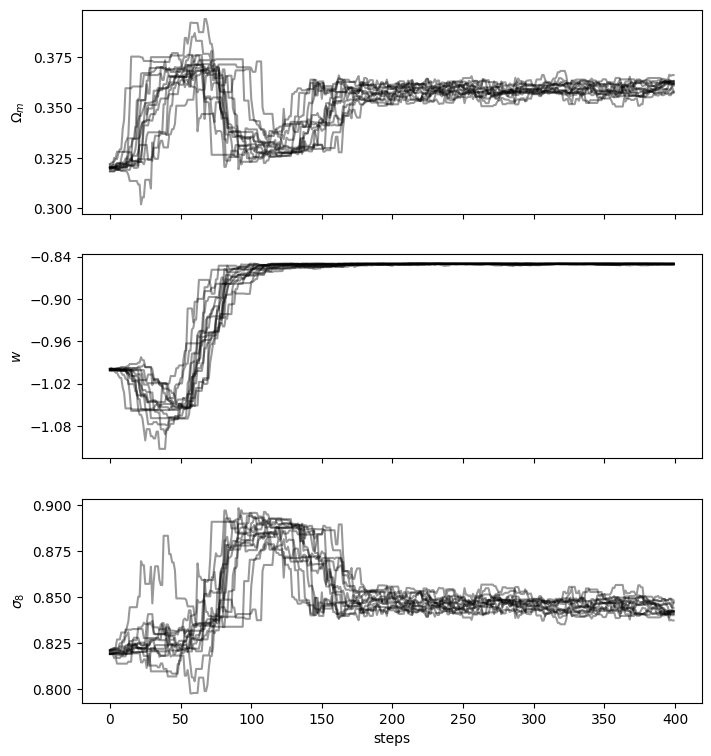

In [27]:
from pylab import *
plt.clf()
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 9))
axes[0].plot(sampler.chain[:, :, 0].T, color="k", alpha=0.4)
axes[0].yaxis.set_major_locator(MaxNLocator(5))
axes[0].set_ylabel("$\Omega_m$")

axes[1].plot(sampler.chain[:, :, 1].T, color="k", alpha=0.4)
axes[1].yaxis.set_major_locator(MaxNLocator(5))
axes[1].set_ylabel("$w$")

axes[2].plot(sampler.chain[:, :, 2].T, color="k", alpha=0.4)
axes[2].yaxis.set_major_locator(MaxNLocator(5))
axes[2].set_ylabel("$\sigma_8$")

axes[2].set_xlabel("steps")

fig.show()

    
names = [r"$\Omega_m$","w",r"$S_8$"]
labels = [r"$\Omega_m$","w",r"$S_8$"]

        #samples = MCSamples(samples=samps, names=names, labels=labels)  

om_mcmc, w_mcmc, s8_mcmc = map(lambda v: (v[1], v[2]-v[1], v[1]-v[0]),zip(*np.percentile(samples_b_2, [16, 50, 84],axis=0)))

print("""MCMC result:
            $\Omega_m$ = {0[0]} + {0[1]} -{0[2]} 
            $w$    = {1[0]} + {1[1]} -{1[2]}
            $\sigma_8$    = {2[0]} + {2[1]} -{2[2]}
        """.format(om_mcmc, w_mcmc, s8_mcmc))


print("Mean acceptance fraction:", np.mean(sampler.acceptance_fraction))
      

In [85]:
sampler.chain[:, 200:, :].reshape(-1,3)

array([[ 0.31674563, -1.01777422,  0.83468923],
       [ 0.31941323, -1.02361238,  0.83083319],
       [ 0.31941323, -1.02361238,  0.83083319],
       ...,
       [ 0.33055274, -1.00138844,  0.81478565],
       [ 0.33055274, -1.00138844,  0.81478565],
       [ 0.33042357, -1.00084457,  0.81499249]])

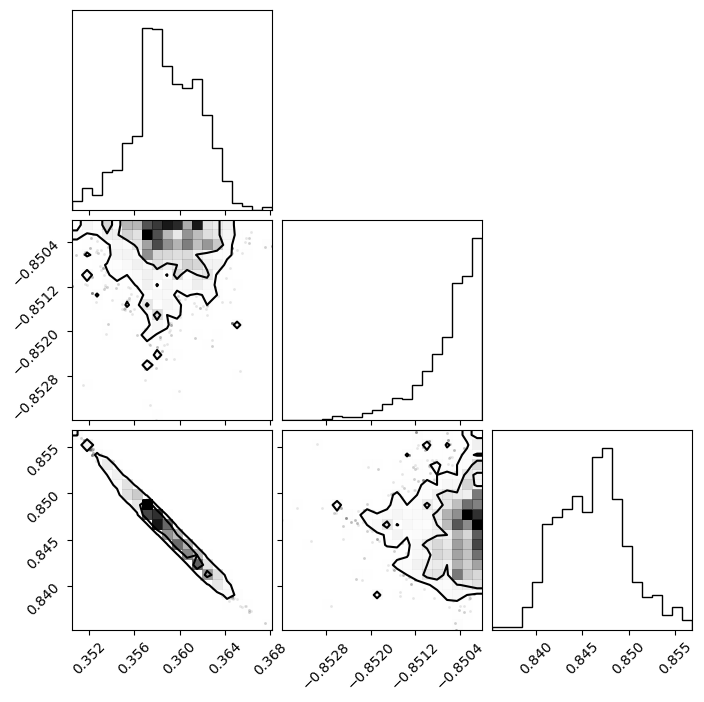

In [28]:
import corner
#samples = sampler.chain[:, 1:, :].reshape((-1, ndim))
fig = corner.corner(sampler.chain[:, 200:, :].reshape(-1,3)
                    ,truths=[0.32,-1,0.83],levels=(0.68,0.95))#,range=[(0.18,0.33),(-1.12,-0.95),(0.72,0.87)])
#plt.savefig('result_baryonmodel17_singlez.pdf')

#np.save('model3_baryons.npy',samples)

In [29]:
from getdist import plots, MCSamples

Removed no burn in


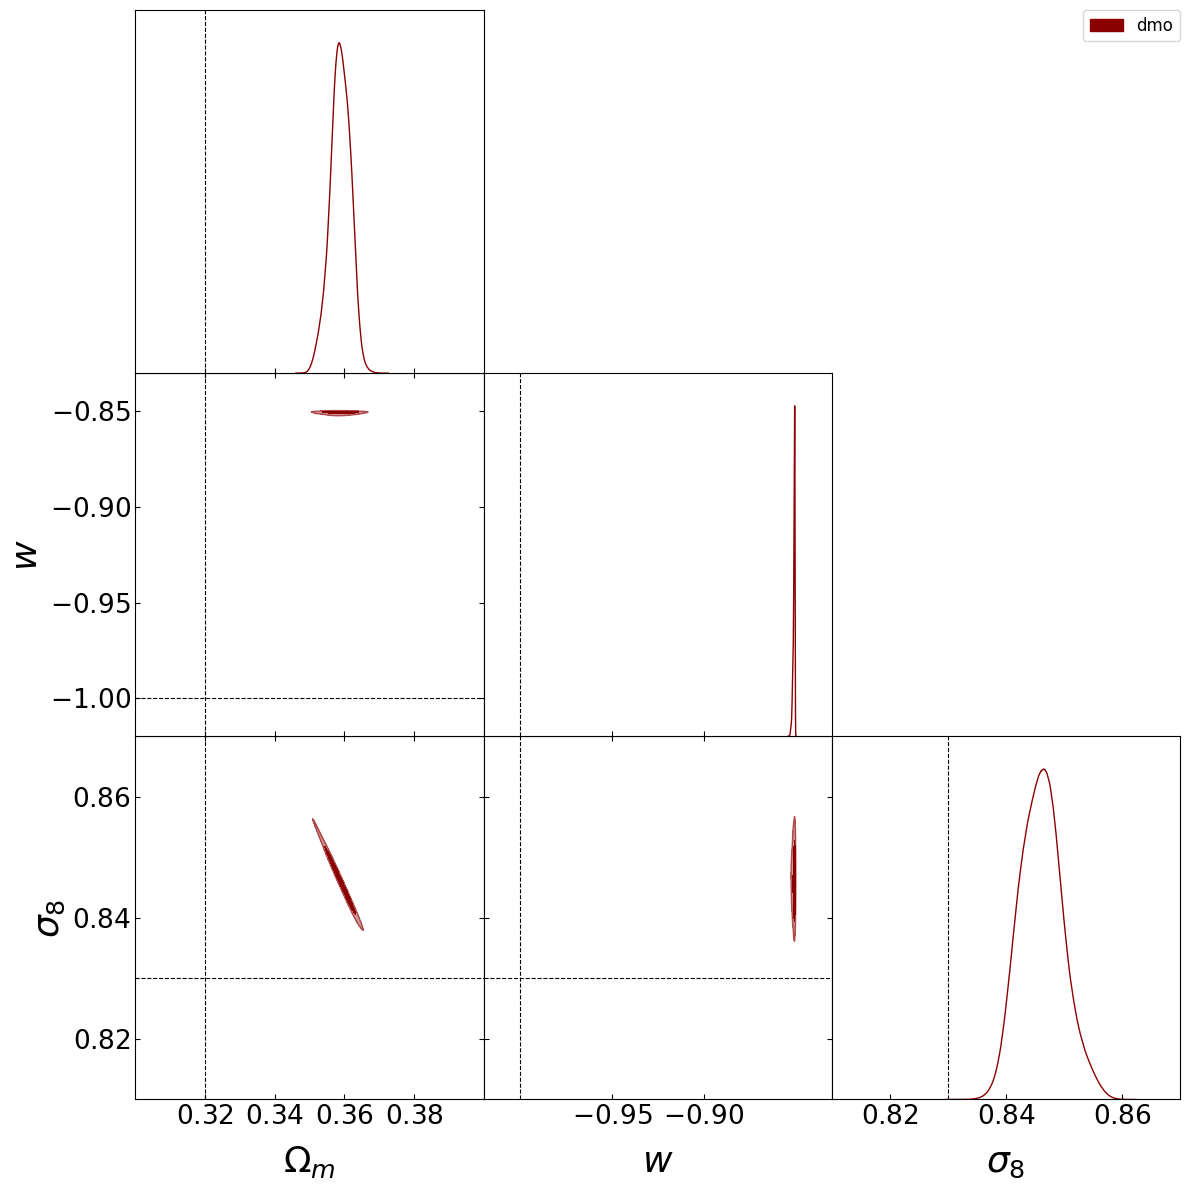

In [36]:
samples_b=sampler.chain[:, 200:, :].reshape(-1,3)
labels1=[r'\Omega_m','w',r'\sigma_8']
parameters=['Om','w','s8']

model4 = MCSamples(samples = samples_b,names = parameters, labels = labels1) 


input1=np.array([0.32,-1.00,0.83])

labels1=[r'\Omega_m','w',r'S_8']

#model_tot = MCSamples(samples = data_tot, weights=weights,names = parameters, labels = labels1)

g = plots.getSubplotPlotter(width_inch=12)

model4.updateSettings({'contours': [0.68, 0.95]})

g.settings.axes_labelsize = 26
g.settings.alpha_filled_add=0.8
g.settings.axes_fontsize = 19
g.settings.legend_fontsize = 12

g.triangle_plot([model4],parameters, 
                legend_labels=['dmo'
                              ],
                markers={"Om":input1[0],'w':input1[1],"s8":input1[2]},
                colors=['darkred','pink'],
                marker_args={'lw':0.8, 'color':'black'},filled=[True,True],
                contour_ls=['-','-'],
                contour_lws=[1,1],
                contour_colors=['darkred','pink'],param_limits={'Om': (0.3, 0.4), 'w': (-1.02, -0.83),'s8': (0.81, 0.87)},
                alphas=[1])


In [ ]:
MCMC result:
            $\Omega_m$ = 0.3247137723388145 + 0.03713158543689371 -0.025330311675136663 
            $w$    = -1.0013360569225753 + 0.08317705674314158 -0.08718988689664409
            $\sigma_8$    = 0.8186583599320092 + 0.041899521290236774 -0.04493302700121815
     